### Decay neutrinos at the $\mu C$ ###

The goal of this notebook is to study the probability of detecting neutrino oscillations from the forward neutrinos produced along a decaying muon beam. Ultimately, we'd like to compare energy ranges of parent muons along different sections of a future muon collider to assess the potential physics reach of a forward neutrino program at the $\mu C$.

In Appendix A of the _Forward neutrino flux_ paper, an expression for the neutrino angular distribution per solid angle as a function of muon energy/boost factor is derived to be $$\frac{d P}{d \Omega} = \frac{1}{4 \pi} \frac{1}{\gamma^2 (1 - \beta cos\theta_{\nu})^2}.$$

Therefore distribution per polar angle is $$ \frac{d P}{d \theta} = \frac{1}{2 \gamma^2} \frac{sin\theta}{(1 - \beta cos\theta)}. $$

This way, the distribution can be used as a measure of $\nu$ flux through a detector face. 

The probability of $\nu$ oscillation is $$P(\nu_{\alpha} \rightarrow \nu_{\beta}) \propto sin^2[ 1.27 * \frac{\Delta m^2}{eV^2} \frac{L}{km} \frac{GeV}{E}],$$

and is maximized for $$ \frac{\Delta m^2 L}{E} \rightarrow 1. $$

Physics.py, imported below, contains the two functions above as well as physical constants and collider section parameters.

In [1]:
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import rc
#rc('font',**{'family':'serif','serif':['Times']})
#rc('text', usetex=True)

import physics

### Approximate average energy of each section ###

In [2]:
for section in physics.sections:
    section['E_nu'] = ( section['E_0'] + section['E_f'] ) / 6
    print(section['name'], 'energy: ', round(section['E_nu'], 3), "GeV")

PA energy:  0.251 GeV
RLA1 energy:  1.042 GeV
RLA2 energy:  11.25 GeV
RCS1 energy:  62.833 GeV
RCS2 energy:  177.333 GeV
RCS3 energy:  375.0 GeV
RCS4 energy:  1083.333 GeV


In [3]:
# this gives another breakdown of available energy levels in our collider:
'''for section in physics.sections:
    print(f'For {section['name']}, ')
    dE = 0
    for i in range(section['n_turns']):
        dE = i * section['E_per_pass']
        print(f'initial energy of pass {i + 1} is {section['E_0'] + dE * i}')'''

"for section in physics.sections:\n    print(f'For {section['name']}, ')\n    dE = 0\n    for i in range(section['n_turns']):\n        dE = i * section['E_per_pass']\n        print(f'initial energy of pass {i + 1} is {section['E_0'] + dE * i}')"

### Probability of $\nu$ oscillation ### 
Comparing energies and lengths

In [4]:
'''# last time we found ideal energies for oscillation at L = 200km to be...
L_det = 200e3
print((2)/(np.pi)*(1.27)*(physics.mass_diff_21)*(L_det / 1000))
print((2)/(np.pi)*(1.27)*(physics.mass_diff_31)*(L_det / 1000))
print('^GeV')'''

"# last time we found ideal energies for oscillation at L = 200km to be...\nL_det = 200e3\nprint((2)/(np.pi)*(1.27)*(physics.mass_diff_21)*(L_det / 1000))\nprint((2)/(np.pi)*(1.27)*(physics.mass_diff_31)*(L_det / 1000))\nprint('^GeV')"

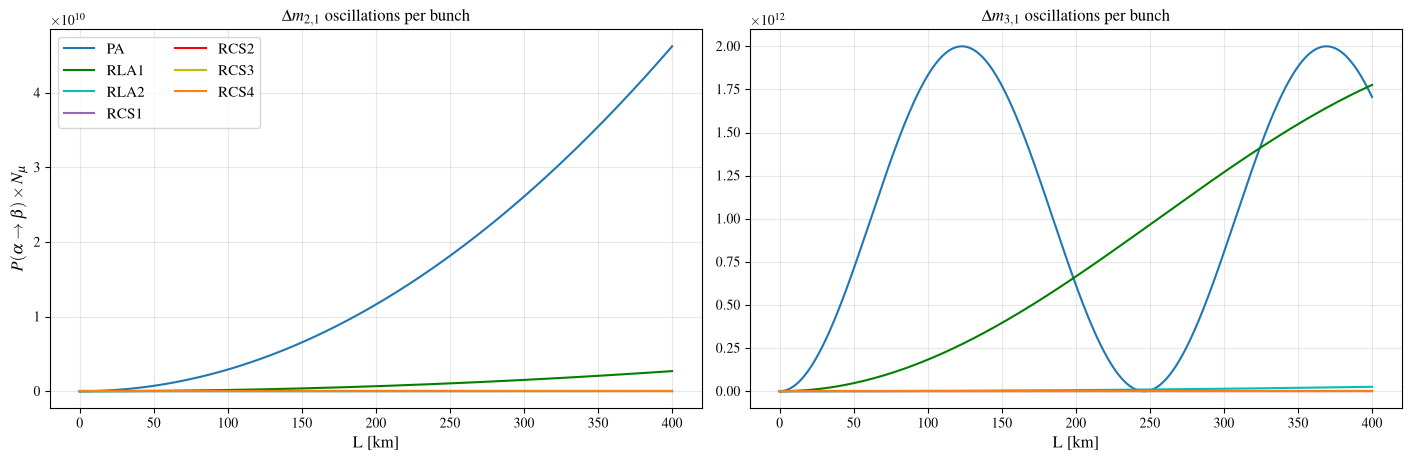

In [5]:
fig, (ax1, ax2) = plt.subplots(ncols=2, nrows=1, figsize=(14, 4.5), layout="constrained")

for section in physics.sections:
    ax1.plot(np.linspace(0, 400, 500), 
            physics.N_mu * physics.prob_of_oscillation(physics.mass_diff_21, section['E_nu'], np.linspace(0, 400e3, 500)), 
            color=f'{section['color']}', label=f'{section['name']}')
    ax2.plot(np.linspace(0, 400, 500), 
                physics.N_mu * physics.prob_of_oscillation(physics.mass_diff_31, section['E_nu'], np.linspace(0, 400e3, 500)), 
                color=f'{section['color']}', label=f'{section['name']}')

ax1.legend(frameon=True, fontsize=11, ncol=2, loc="upper left")

ax1.set_xlabel(r"L [km]", fontsize=12)
ax1.set_ylabel(r"$P(\alpha \rightarrow \beta) \times N_{\mu}$", fontsize=12)
ax1.set_title(rf"$\Delta m_{'{2,1}'}$ oscillations per bunch", fontsize=12)
ax1.grid(True, which="major", ls="-", alpha=0.3)

ax2.set_xlabel(r"L [km]", fontsize=12)
ax2.set_title(rf"$\Delta m_{'{3,1}'}$ oscillations per bunch", fontsize=12)
ax2.grid(True, which="major", ls="-", alpha=0.3)

In [6]:
# here's the general script for looking at oscillation
'''fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(7, 4.5), layout="constrained")

for section in physics.sections:
# plotting over lengths
    ax.plot(np.linspace(0, 400, 500), 
            #physics.prob_of_oscillation(physics.mass_diff_31, section['E_nu'], np.linspace(0, 400e3, 500)), 
            physics.N_mu * ( physics.prob_of_oscillation(physics.mass_diff_31, section['E_nu'], np.linspace(0, 400e3, 500)) ), 
            color=f'{section['color']}', label=f'{section['name']}')

ax.legend(frameon=False, fontsize=11, ncol=2, loc="upper right")

ax.set_xlabel(r"L [km]", fontsize=12)
ax.set_ylabel(r"$P(\alpha \rightarrow \beta) * N_{\mu}$", fontsize=12)
ax.set_title(rf"$\Delta m_{'{3,1}'}$ oscillations per bunch", fontsize=12)
ax.grid(True, which="major", ls="-", alpha=0.3)'''

<>:2: SyntaxWarning: invalid escape sequence '\m'
<>:2: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_65067/1656999073.py:2: SyntaxWarning: invalid escape sequence '\m'
  '''fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(7, 4.5), layout="constrained")


'fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(7, 4.5), layout="constrained")\n\nfor section in physics.sections:\n# plotting over lengths\n    ax.plot(np.linspace(0, 400, 500), \n            #physics.prob_of_oscillation(physics.mass_diff_31, section[\'E_nu\'], np.linspace(0, 400e3, 500)), \n            physics.N_mu * ( physics.prob_of_oscillation(physics.mass_diff_31, section[\'E_nu\'], np.linspace(0, 400e3, 500)) ), \n            color=f\'{section[\'color\']}\', label=f\'{section[\'name\']}\')\n\nax.legend(frameon=False, fontsize=11, ncol=2, loc="upper right")\n\nax.set_xlabel(r"L [km]", fontsize=12)\nax.set_ylabel(r"$P(\x07lpha \rightarrow \x08eta) * N_{\\mu}$", fontsize=12)\nax.set_title(rf"$\\Delta m_{\'{3,1}\'}$ oscillations per bunch", fontsize=12)\nax.grid(True, which="major", ls="-", alpha=0.3)'

In [7]:
# here's a table with probabilities for a fixed length
'''print(rf'Probability of $\Delta m_{'{2,1}'}$ oscillation for L = 200km')
print(rf'----------------------------------------------------------')

for section in physics.sections:
    print(rf'{section['name']}: {physics.prob_of_oscillation(physics.mass_diff_21, section['E_nu'], 200e3)}')


print(rf'Probability of $\Delta m_{'{3,1}'}$ oscillation for L = 200km')
print(rf'----------------------------------------------------------')

for section in physics.sections:
    print(rf'{section['name']}: {physics.prob_of_oscillation(physics.mass_diff_31, section['E_nu'], 200e3)}')'''

<>:2: SyntaxWarning: invalid escape sequence '\D'
<>:2: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_65067/848596501.py:2: SyntaxWarning: invalid escape sequence '\D'
  '''print(rf'Probability of $\Delta m_{'{2,1}'}$ oscillation for L = 200km')


"print(rf'Probability of $\\Delta m_{'{2,1}'}$ oscillation for L = 200km')\nprint(rf'----------------------------------------------------------')\n\nfor section in physics.sections:\n    print(rf'{section['name']}: {physics.prob_of_oscillation(physics.mass_diff_21, section['E_nu'], 200e3)}')\n\n\nprint(rf'Probability of $\\Delta m_{'{3,1}'}$ oscillation for L = 200km')\nprint(rf'----------------------------------------------------------')\n\nfor section in physics.sections:\n    print(rf'{section['name']}: {physics.prob_of_oscillation(physics.mass_diff_31, section['E_nu'], 200e3)}')"

## $\nu$ Kinematics ##

In [23]:
# check
physics.integrated_angular_dist(0, np.pi, physics.gamma(5e3), physics.beta(5e3))

np.float64(0.999999864556696)

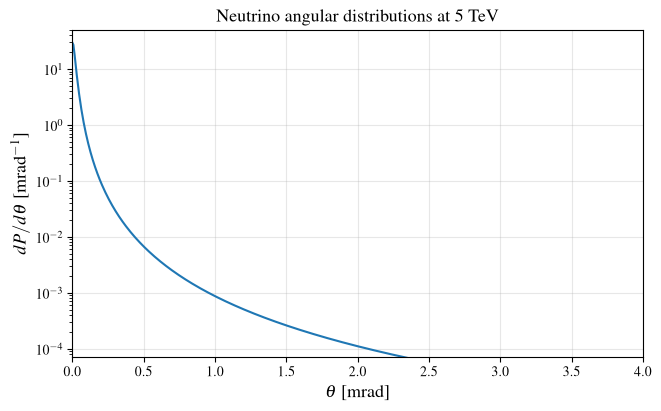

In [8]:
E_mu = 5000 # GeV = 5 TeV
L_det = 5e3 # m = 5 km

beta = physics.beta(E_mu)
gamma = physics.gamma(E_mu)

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(6.5, 4), layout="constrained")

# plotting to 4 mrads
# the 1/1000/100 thing is to prevent plotting for theta=0 where P=0
# dividing by 1000 is because the paper plots per 1 mrad, for some reason
ax.plot(np.linspace(0 + 1/1000/100, 4, physics.n_samples), 
        physics.angular_dist(np.linspace(1/1000/100, 4/1000, physics.n_samples), gamma, beta) / 1000,
        color='tab:blue')

ax.set_yscale("log")
ax.set_ylim(10**(-4.15), 10**(1.7))
ax.set_xlim(0,4)
ax.set_xlabel(r"$\theta$ [mrad]", fontsize=13)
ax.set_ylabel(r"$dP / d \theta$ [mrad$^{-1}$]", fontsize=13)
ax.set_title(rf"Neutrino angular distributions at 5 TeV", fontsize=13)
ax.grid(True, which="major", ls="-", alpha=0.3)

In [9]:
# colormap representation
# i still haven't figured this one out...

'''# 1 m radius detector
w_size = 200 # cm
x = np.linspace(-w_size, w_size, physics.n_samples)
y = np.linspace(-w_size, w_size, physics.n_samples)

X, Y = np.meshgrid(x, y)

plt.pcolormesh(X, Y, physics.N_mu * physics.angular_dist((np.atan((np.sqrt((X/100)**2 + (Y/100)**2))/L_det)), gamma, beta))

plt.colorbar()

plt.xlim(-w_size, w_size)
plt.ylim(-w_size, w_size)
plt.xlabel('x [cm]', fontsize=14)
plt.ylabel('y [cm]', fontsize=14)
plt.title(rf'$E_{'{\mu}'}$ ={E_mu / 1000} TeV, $L_{'{det}'}$ ={L_det/1000} km', fontsize=14)'''

<>:4: SyntaxWarning: invalid escape sequence '\m'
<>:4: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_65067/312892106.py:4: SyntaxWarning: invalid escape sequence '\m'
  '''# 1 m radius detector


"# 1 m radius detector\nw_size = 200 # cm\nx = np.linspace(-w_size, w_size, physics.n_samples)\ny = np.linspace(-w_size, w_size, physics.n_samples)\n\nX, Y = np.meshgrid(x, y)\n\nplt.pcolormesh(X, Y, physics.N_mu * physics.angular_dist((np.atan((np.sqrt((X/100)**2 + (Y/100)**2))/L_det)), gamma, beta))\n\nplt.colorbar()\n\nplt.xlim(-w_size, w_size)\nplt.ylim(-w_size, w_size)\nplt.xlabel('x [cm]', fontsize=14)\nplt.ylabel('y [cm]', fontsize=14)\nplt.title(rf'$E_{'{\\mu}'}$ ={E_mu / 1000} TeV, $L_{'{det}'}$ ={L_det/1000} km', fontsize=14)"

### Comparing collider section energies ###

In [10]:
# detector angular acceptance scales linearly with detector radius
# ^ this will be important to keep in mind when calculating fluxes of a given setup

'''# for L = 200km, R = 10m, the maximum accepted angle is
# print(np.atan(10/1000/200) * 1000, "mrad")

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(3, 2.5), layout="constrained")
ax.plot(np.linspace(0, 50, 100), np.atan(np.linspace(0, 50, 100)/1000/200) * 1000, color='tab:red')

ax.set_ylabel(r"$\theta_{max}$ [mrad]", fontsize=12)
ax.set_xlabel(r"R [m]", fontsize=12)
ax.set_title('Detector angular acceptance vs radius for L=200km')
ax.grid(True, which="major", ls="-", alpha=0.3)'''

'# for L = 200km, R = 10m, the maximum accepted angle is\n# print(np.atan(10/1000/200) * 1000, "mrad")\n\nfig, ax = plt.subplots(ncols=1, nrows=1, figsize=(3, 2.5), layout="constrained")\nax.plot(np.linspace(0, 50, 100), np.atan(np.linspace(0, 50, 100)/1000/200) * 1000, color=\'tab:red\')\n\nax.set_ylabel(r"$\theta_{max}$ [mrad]", fontsize=12)\nax.set_xlabel(r"R [m]", fontsize=12)\nax.set_title(\'Detector angular acceptance vs radius for L=200km\')\nax.grid(True, which="major", ls="-", alpha=0.3)'

/tmp/ipykernel_65067/857172585.py:29: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  ax.set_ylim(0, 10**(2))


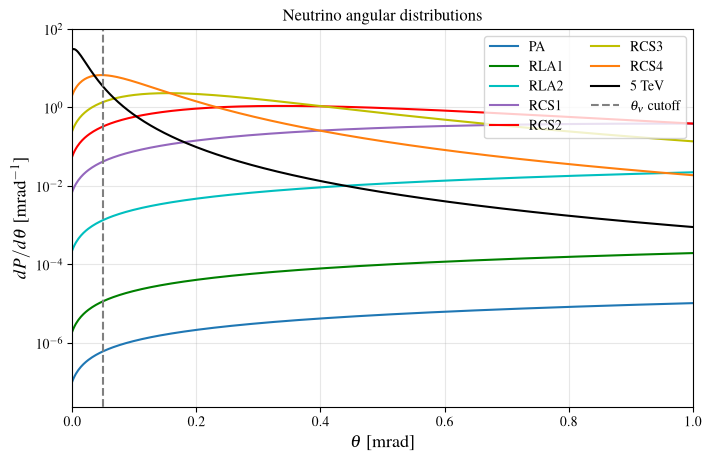

In [67]:
L_det = 200e3 # m = 200km

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(7, 4.5), layout="constrained")

for section in physics.sections:
    ax.plot(np.linspace(0+ 1/1000/100, 1, physics.n_samples), 
            physics.angular_dist(np.linspace(0 + 1/1000/100, 1/1000, physics.n_samples), (physics.gamma(section['E_nu'])), (physics.beta(section['E_nu']))) / 1000, 
            color=f'{section['color']}', label=f'{section['name']}')

# 5 TeV
ax.plot(np.linspace(0+ 1/1000/100, 1, physics.n_samples), 
            physics.angular_dist(np.linspace(0 + 1/1000/100, 1/1000, physics.n_samples), (physics.gamma(5e3)), (physics.beta(5e3))) / 1000, 
            color='black', label='5 TeV')

'''# 1.5 Tev
ax.plot(np.linspace(0+ 1/1000/100, 1, physics.n_samples), 
            physics.angular_dist(np.linspace(0 + 1/1000/100, 1/1000, physics.n_samples), (physics.gamma(1.5e3)), (physics.beta(1.5e3))) / 1000, 
            color='grey', label='1.5 TeV')'''

# for L = 200km, R = 10m, maximum accepted theta is
#print(np.atan(10/1000/200) * 1000, "mrad")

ax.vlines(np.atan(10/1000/200) * 1000, 0, 10e5, linestyles='dashed', colors='grey', label=r'$\theta_{\nu}$ cutoff')

ax.legend(frameon=True, fontsize=10, ncol=2, loc="upper right")
ax.set_yscale("log")
ax.set_xlim(0,1)
#ax.set_ylim(0,10e5)
ax.set_ylim(0, 10**(2))
ax.set_xlabel(r"$\theta$ [mrad]", fontsize=13)
ax.set_ylabel(r"$dP / d \theta$ [mrad$^{-1}$]", fontsize=13)
ax.set_title(rf'Neutrino angular distributions', fontsize=12)
ax.grid(True, which="major", ls="-", alpha=0.3)

In [34]:
# the actual probabilitiy of detecting a neutrino within the allowed angular acceptance
# range for a given detector setup is the area under this curve ^ !

# angular cutoff for this setup is np.atan(10/1000/200) * 1000, "mrad"
theta_accept = np.atan(10/1000/200) # rad

# here's a table
print('Probability of detecting neutrinos at a 200km away, 10m radius detector')
print('-----------------------------------------------------------------------')
for section in physics.sections:
    print(f'{section['name']}: {physics.integrated_angular_dist(0, theta_accept, physics.gamma(section['E_nu']), physics.beta(section['E_nu']))}')


Probability of detecting neutrinos at a 200km away, 10m radius detector
-----------------------------------------------------------------------
PA: 1.2809333298690035e-08
RLA1: 2.417407739153184e-07
RLA2: 2.8340584338980177e-05
RCS1: 0.0008833463430927275
RCS2: 0.006993075068273961
RCS3: 0.030530363949544715
RCS4: 0.20812189587238944


314.0
401.2
488.4
575.6
662.8


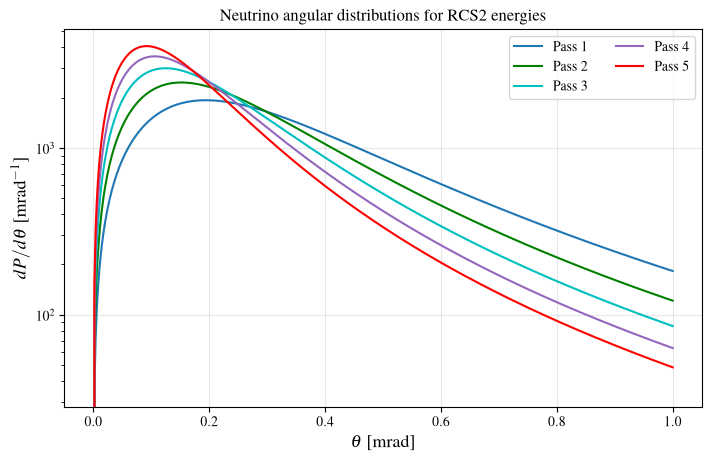

In [ ]:
# distributions for energies of a single ring

section = physics.RCS2

#print(section['E_0'])
#print(section['E_f'])
#print(section['n_turns'])

section['E_per_pass'] = ( section['E_f'] - section['E_0'] ) / section['n_turns']

#print(section['E_per_pass'])

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(7, 4.5), layout="constrained")

for i in range(section['n_turns']):
    dE = section['E_0'] + (i * section['E_per_pass'])
    print(dE)
    ax.plot(np.linspace(0, 1, physics.n_samples), 
            physics.angular_dist(np.linspace(0, 1/1000, physics.n_samples), (physics.gamma(dE)), (physics.beta(dE))), 
            color=f'{physics.list_of_colors[i]}', label=f'Pass {i + 1}')


ax.legend(frameon=True, fontsize=10, ncol=2, loc="upper right")
ax.set_yscale("log")
#ax.set_xlim(0,1)
#ax.set_ylim(0,1)
ax.set_xlabel(r"$\theta$ [mrad]", fontsize=13)
ax.set_ylabel(r"$dP / d \theta$ [mrad$^{-1}$]", fontsize=13)
ax.set_title(rf'Neutrino angular distributions for {section['name']} energies', fontsize=12)
ax.grid(True, which="major", ls="-", alpha=0.3)

### Kinematics and oscillation — trading off between energy and baseline length ###

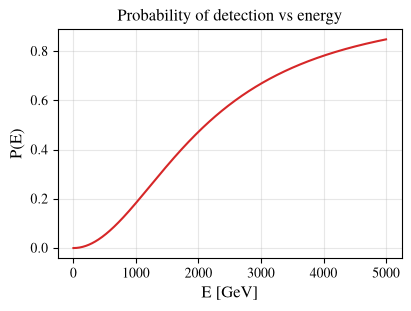

In [45]:
# in general, as a function of energy, this probability is...

# from 1 GeV to 5 Tev
E_range = np.linspace(1, 5e3, physics.n_samples)

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(4, 3), layout="constrained")
ax.plot(E_range, 
        physics.integrated_angular_dist(0, theta_accept, physics.gamma(E_range), physics.beta(E_range)),
        color='tab:red')

ax.set_ylabel(r"P(E)", fontsize=12)
ax.set_xlabel(r"E [GeV]", fontsize=12)
ax.set_title('Probability of detection vs energy')
ax.grid(True, which="major", ls="-", alpha=0.3)

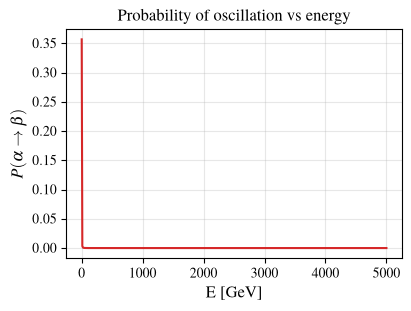

In [46]:
# similarly...
# from 1 GeV to 5 Tev
E_range = np.linspace(1, 5e3, physics.n_samples)

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(4, 3), layout="constrained")
ax.plot(E_range, 
        physics.prob_of_oscillation(physics.mass_diff_31, E_range, L_det),
        color='tab:red')

ax.set_ylabel(r"$P(\alpha \rightarrow \beta)$", fontsize=12)
ax.set_xlabel(r"E [GeV]", fontsize=12)
ax.set_title('Probability of oscillation vs energy')
ax.grid(True, which="major", ls="-", alpha=0.3)

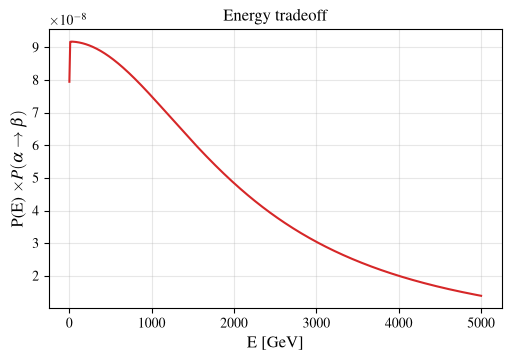

In [69]:
# and finally...

# from 1 GeV to 5 Tev
E_range = np.linspace(1, 5e3, physics.n_samples)

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(5, 3.5), layout="constrained")
ax.plot(E_range, 
        physics.integrated_angular_dist(0, theta_accept, physics.gamma(E_range), physics.beta(E_range)) * physics.prob_of_oscillation(physics.mass_diff_31, E_range, L_det),
        color='tab:red')

ax.set_ylabel(r"P(E) $ \times P(\alpha \rightarrow \beta)$ ", fontsize=12)
ax.set_xlabel(r"E [GeV]", fontsize=12)
ax.set_title('Energy tradeoff')
ax.grid(True, which="major", ls="-", alpha=0.3)

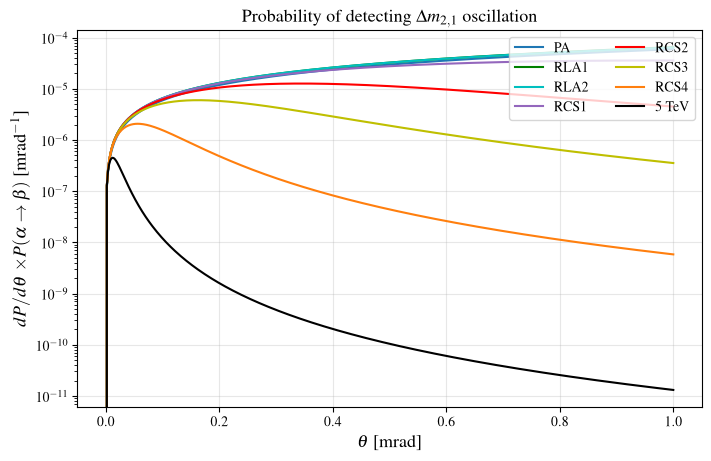

In [48]:
L_det = 200e3 # m = 200km

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(7, 4.5), layout="constrained")

for section in physics.sections:
    ax.plot(np.linspace(0, 1, physics.n_samples), 
            physics.prob_of_oscillation(physics.mass_diff_21, section['E_nu'], L_det) * 
            physics.angular_dist(np.linspace(0, 1/1000, physics.n_samples), (physics.gamma(section['E_nu'])), (physics.beta(section['E_nu']))), 
            color=f'{section['color']}', label=f'{section['name']}')

# 5 TeV
ax.plot(np.linspace(0, 1, physics.n_samples), 
            physics.prob_of_oscillation(physics.mass_diff_21, 5e3, L_det) * 
            physics.angular_dist(np.linspace(0, 1/1000, physics.n_samples), (physics.gamma(5e3)), (physics.beta(5e3))), 
            color='black', label='5 TeV')



ax.legend(frameon=True, fontsize=10, ncol=2, loc="upper right")
ax.set_yscale("log")
#ax.set_xlim(0,1)
#ax.set_ylim(0,1)
ax.set_xlabel(r"$\theta$ [mrad]", fontsize=13)
ax.set_ylabel(r"$dP / d \theta$ $\times P(\alpha \rightarrow \beta)$ [mrad$^{-1}$]", fontsize=13)
ax.set_title(r'Probability of detecting $\Delta m_{2,1}$ oscillation', fontsize=13)
ax.grid(True, which="major", ls="-", alpha=0.3)

Looks like low energies favored for oscillation beat high energies favored for kinematics! 

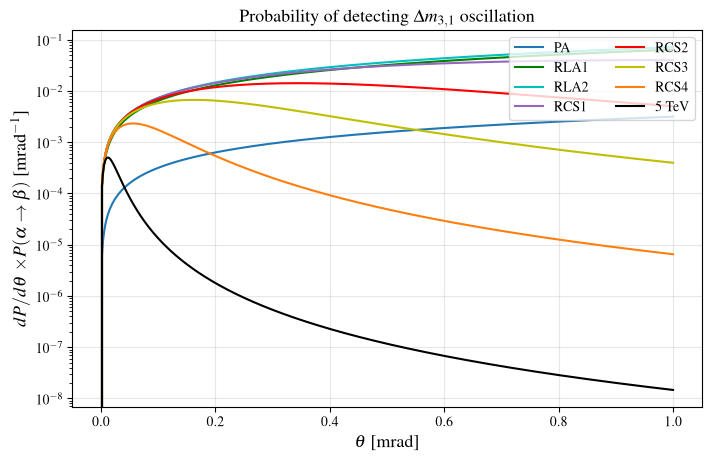

In [49]:
L_det = 200e3 # m = 200km

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(7, 4.5), layout="constrained")

for section in physics.sections:
    ax.plot(np.linspace(0, 1, physics.n_samples), 
            physics.prob_of_oscillation(physics.mass_diff_31, section['E_nu'], L_det) * 
            physics.angular_dist(np.linspace(0, 1/1000, physics.n_samples), (physics.gamma(section['E_nu'])), (physics.beta(section['E_nu']))), 
            color=f'{section['color']}', label=f'{section['name']}')

# 5 TeV
ax.plot(np.linspace(0, 1, physics.n_samples), 
            physics.prob_of_oscillation(physics.mass_diff_31, 5e3, L_det) * 
            physics.angular_dist(np.linspace(0, 1/1000, physics.n_samples), (physics.gamma(5e3)), (physics.beta(5e3))), 
            color='black', label='5 TeV')


ax.legend(frameon=True, fontsize=10, ncol=2, loc="upper right")
ax.set_yscale("log")
#ax.set_xlim(0,1)
#ax.set_ylim(0,1)
ax.set_xlabel(r"$\theta$ [mrad]", fontsize=13)
ax.set_ylabel(r"$dP / d \theta$ $\times P(\alpha \rightarrow \beta)$ [mrad$^{-1}$]", fontsize=13)
ax.set_title(r'Probability of detecting $\Delta m_{3,1}$ oscillation', fontsize=13)
ax.grid(True, which="major", ls="-", alpha=0.3)

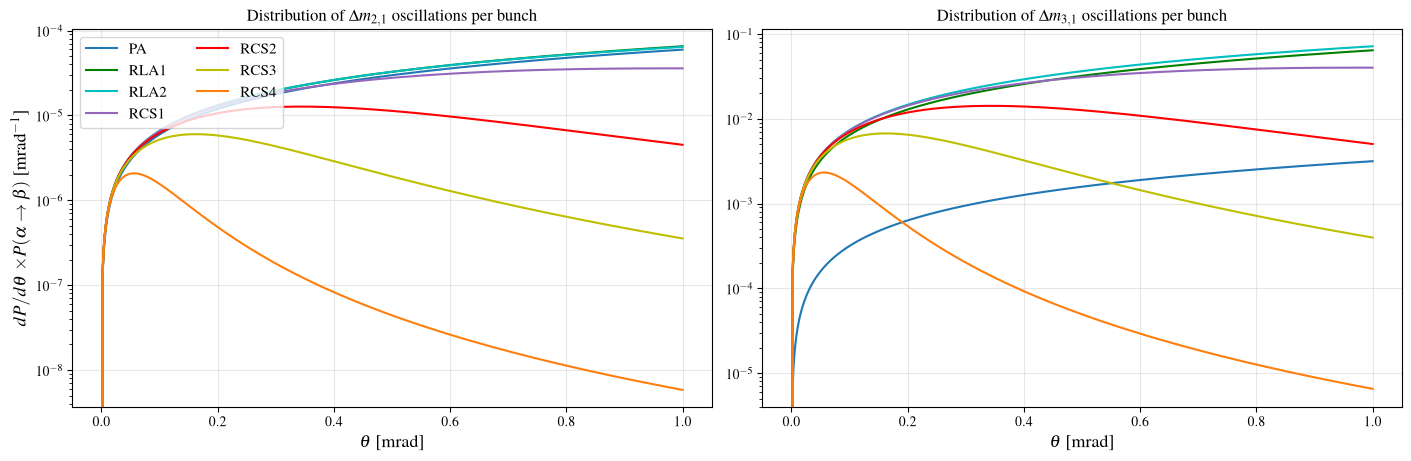

In [50]:
fig, (ax1, ax2) = plt.subplots(ncols=2, nrows=1, figsize=(14, 4.5), layout="constrained")

for section in physics.sections:
    ax1.plot(np.linspace(0, 1, physics.n_samples), 
            physics.prob_of_oscillation(physics.mass_diff_21, section['E_nu'], 200e3) * 
            physics.angular_dist(np.linspace(0, 1/1000, physics.n_samples), (physics.gamma(section['E_nu'])), (physics.beta(section['E_nu']))), 
            color=f'{section['color']}', label=f'{section['name']}')
    ax2.plot(np.linspace(0, 1, physics.n_samples), 
            physics.prob_of_oscillation(physics.mass_diff_31, section['E_nu'], 200e3) * 
            physics.angular_dist(np.linspace(0, 1/1000, physics.n_samples), (physics.gamma(section['E_nu'])), (physics.beta(section['E_nu']))), 
            color=f'{section['color']}', label=f'{section['name']}')

ax1.legend(frameon=True, fontsize=11, ncol=2, loc="upper left")

ax1.set_yscale("log")
ax1.set_xlabel(r"$\theta$ [mrad]", fontsize=13)
ax1.set_ylabel(r"$dP / d \theta$ $\times P(\alpha \rightarrow \beta)$ [mrad$^{-1}$]", fontsize=13)
ax1.set_title(rf"Distribution of $\Delta m_{'{2,1}'}$ oscillations per bunch", fontsize=12)
ax1.grid(True, which="major", ls="-", alpha=0.3)

ax2.set_yscale("log")
ax2.set_xlabel(r"$\theta$ [mrad]", fontsize=13)
ax2.set_title(rf"Distribution of $\Delta m_{'{3,1}'}$ oscillations per bunch", fontsize=12)
ax2.grid(True, which="major", ls="-", alpha=0.3)